# E-Commerce Funnel Analysis

## Libraries

In [8]:
import math
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 50)
print("All libraries are ready to use.")

All libraries are ready to use.


### Configuration


In [9]:
DATA_DIR = Path(".")  # the notebook sits in the same folder as the CSV files (main_project)
FILES = {
    "2019-10": "2019-Oct.csv", "2019-11": "2019-Nov.csv", "2019-12": "2019-Dec.csv",
    "2020-01": "2020-Jan.csv", "2020-02": "2020-Feb.csv",
}
MONTH_ORDER = list(FILES)
COMPARE_MONTHS = ("2020-01", "2020-02")  # the task's January vs February comparison (consecutive months)
NOTE_MONTHS = COMPARE_MONTHS             # the reference notes describe the Jan + Feb files
USER_SAMPLE_PERCENT = 100                # 100 = all users; e.g. 20 keeps a deterministic 20% of users (dry run)


In [10]:

READ_COLUMNS = [
    "event_time", "event_type", "product_id", "category_code",
    "brand", "price", "user_id", "user_session",
]
FUNNEL_STAGES = ["view", "cart", "purchase"]
FUNNEL_MODE = "strict"  # "strict" or "loose"


In [11]:

TOP_N_CATEGORIES = 8
TOP_N_BRANDS = 10
MIN_VIEWERS = 100       # small-sample guard for rankings
VIEW_QUANTILE = 0.95    # "high view" = top 5% of products by unique viewers
IQR_MULTIPLIER = 1.5
ALPHA = 0.05

NOTE = {
    "rows_jan": 2_600_000, "rows_feb": 1_700_000,
    "view_share": 85.1, "cart_share": 8.7, "purchase_share": 6.2,
    "view_to_cart": 10.2, "cart_to_purchase": 71.4, "view_to_purchase": 7.3,
    "feb_minus_jan_pp": 0.8, "accessories_rate": 12.1,
    "top5_brand_share": 34.0, "avg_basket": 26.8, "max_basket": 2140.0,
}

## 1. Data Overview and Cleaning



### Loading

In [12]:
def load_month(path: Path, month: str) -> pd.DataFrame:
    """Read one monthly file with memory-friendly dtypes and a month label."""
    if not path.exists():
        raise FileNotFoundError(f"{path} not found. Put the Kaggle CSV files next to the notebook.")
    header = pd.read_csv(path, nrows=0).columns
    missing = set(READ_COLUMNS) - set(header)
    if missing:
        raise ValueError(f"{path.name} is missing columns: {sorted(missing)}")

    frame = pd.read_csv(
        path,
        usecols=READ_COLUMNS,
        dtype={
            "event_type": "category", "product_id": "int64", "category_code": "category",
            "brand": "category", "price": "float64", "user_id": "int64", "user_session": "str",
        },
    )
    if USER_SAMPLE_PERCENT < 100:  # deterministic per-user sample: funnel rates stay unbiased, counts shrink
        frame = frame[frame["user_id"] % 100 < USER_SAMPLE_PERCENT].copy()
    frame["event_time"] = pd.to_datetime(frame["event_time"], utc=True).dt.tz_localize(None)
    frame["session_id"] = pd.util.hash_pandas_object(frame["user_session"], index=False)
    frame = frame.drop(columns="user_session")
    frame["month"] = pd.Categorical([month] * len(frame), categories=MONTH_ORDER)
    return frame


def concat_monthly(frames: list[pd.DataFrame]) -> pd.DataFrame:
    """Concatenate frames while keeping categorical columns categorical."""
    categorical_cols = [c for c in frames[0].columns if isinstance(frames[0][c].dtype, pd.CategoricalDtype)]
    for col in categorical_cols:
        union = frames[0][col].cat.categories
        for frame in frames[1:]:
            union = union.union(frame[col].cat.categories)
        for frame in frames:
            frame[col] = frame[col].cat.set_categories(union)
    return pd.concat(frames, ignore_index=True)


df = concat_monthly([load_month(DATA_DIR / name, month) for month, name in FILES.items()])
print(f"Rows × columns : {df.shape[0]:,} × {df.shape[1]}")

Rows × columns : 20,692,840 × 9


### First look


In [13]:
rows_by_month = df["month"].value_counts().reindex(MONTH_ORDER)
print("Rows by month:")
for month in MONTH_ORDER:
    print(f"  {month} : {rows_by_month[month]:>10,}")
print()


Rows by month:
  2019-10 :  4,102,283
  2019-11 :  4,635,837
  2019-12 :  3,533,286
  2020-01 :  4,264,752
  2020-02 :  4,156,682



In [14]:

event_day = df["event_time"].dt.normalize()
month_coverage = pd.DataFrame({
    "rows": df.groupby("month", observed=True).size(),
    "first_event": df.groupby("month", observed=True)["event_time"].min(),
    "last_event": df.groupby("month", observed=True)["event_time"].max(),
    "active_days": event_day.groupby(df["month"], observed=True).nunique(),
})
display(month_coverage)


,rows,first_event,last_event,active_days
month,,,,
2019-10,4102283,2019-10-01 00:00:00,2019-10-31 23:59:54,31
2019-11,4635837,2019-11-01 00:00:02,2019-11-30 23:59:58,30
2019-12,3533286,2019-12-01 00:00:00,2019-12-31 23:59:57,31
2020-01,4264752,2020-01-01 00:00:00,2020-01-31 23:59:58,31
2020-02,4156682,2020-02-01 00:00:01,2020-02-29 23:59:59,29


In [15]:

display(df.head())
df.info(memory_usage="deep")

,event_time,event_type,product_id,category_code,brand,price,user_id,session_id,month
0,2019-10-01 00:00:00,cart,5773203,NaN,runail,2.62,463240011,756787270281216393,2019-10
1,2019-10-01 00:00:03,cart,5773353,NaN,runail,2.62,463240011,756787270281216393,2019-10
2,2019-10-01 00:00:07,cart,5881589,NaN,lovely,13.48,429681830,3949948668801078067,2019-10
3,2019-10-01 00:00:07,cart,5723490,NaN,runail,2.62,463240011,756787270281216393,2019-10
4,2019-10-01 00:00:15,cart,5881449,NaN,lovely,0.56,429681830,3949948668801078067,2019-10


<class 'pandas.DataFrame'>
RangeIndex: 20692840 entries, 0 to 20692839
Data columns (total 9 columns):
 #   Column         Dtype         
---  ------         -----         
 0   event_time     datetime64[us]
 1   event_type     category      
 2   product_id     int64         
 3   category_code  category      
 4   brand          category      
 5   price          float64       
 6   user_id        int64         
 7   session_id     uint64        
 8   month          category      
dtypes: category(4), datetime64[us](1), float64(1), int64(2), uint64(1)
memory usage: 888.1 MB


In [16]:
missing_summary = pd.DataFrame({
    "missing": df.isna().sum(),
    "missing_%": df.isna().mean() * 100,
})
display(missing_summary)


,missing,missing_%
event_time,0,0.00
event_type,0,0.00
product_id,0,0.00
category_code,20339246,98.29
brand,8757117,42.32
price,0,0.00
user_id,0,0.00
session_id,0,0.00
month,0,0.00


In [17]:

print(f"Exact duplicate rows : {df.duplicated().sum():,}")
print()
print("Unique values:")
print(f"  users      : {df['user_id'].nunique():,}")
print(f"  products   : {df['product_id'].nunique():,}")
print(f"  sessions   : {df['session_id'].nunique():,}")
print(f"  categories : {df['category_code'].nunique():,}")
print(f"  brands     : {df['brand'].nunique():,}")

Exact duplicate rows : 1,109,098

Unique values:
  users      : 1,639,358
  products   : 54,571
  sessions   : 4,535,942
  categories : 12
  brands     : 273


### Event type distribution


In [18]:
event_distribution = df["event_type"].value_counts().rename("events").to_frame()
event_distribution["share_%"] = event_distribution["events"] / event_distribution["events"].sum() * 100
display(event_distribution)


,events,share_%
event_type,,
view,9657821,46.67
cart,5768333,27.88
remove_from_cart,3979679,19.23
purchase,1287007,6.22


In [19]:

event_by_month = pd.crosstab(df["month"], df["event_type"], normalize="index") * 100
print("\nEvent type share by month, %:")
display(event_by_month)



Event type share by month, %:


event_type,cart,purchase,remove_from_cart,view
month,,,,
2019-10,30.04,5.99,18.58,45.39
2019-11,28.30,6.95,19.96,44.78
2019-12,26.24,6.03,18.81,48.92
2020-01,26.93,6.19,19.11,47.78
2020-02,27.63,5.82,19.54,47.00


In [20]:

funnel_events = df[df["event_type"].isin(FUNNEL_STAGES)]
print(f"Events excluded from the funnel : {len(df) - len(funnel_events):,} "
      f"({(len(df) - len(funnel_events)) / len(df) * 100:.2f}% of all events)")

Events excluded from the funnel : 3,979,679 (19.23% of all events)


### Data-quality checks and cleaning decisions

In [21]:
purchases_all = df[df["event_type"] == "purchase"]


In [22]:

expected_period = {month: int(month.replace("-", "")) for month in MONTH_ORDER}
event_period = df["event_time"].dt.year * 100 + df["event_time"].dt.month
month_mismatch = sum(
    int(((df["month"] == month) & (event_period != period)).sum())
    for month, period in expected_period.items()
)

In [23]:
non_positive_price = int((df["price"] <= 0).sum())
missing_price_purchases = int(purchases_all["price"].isna().sum())


In [24]:

print(f"Rows whose timestamp month differs from the file month : {month_mismatch:,}")
print(f"Rows with price <= 0                                   : {non_positive_price:,}")
print(f"Purchase events with missing price                     : {missing_price_purchases:,}")
print(f"category_code missing (all events)                      : {df['category_code'].isna().mean() * 100:.1f}%")
print(f"brand missing (all events)                              : {df['brand'].isna().mean() * 100:.1f}%")

Rows whose timestamp month differs from the file month : 0
Rows with price <= 0                                   : 104,288
Purchase events with missing price                     : 0
category_code missing (all events)                      : 98.3%
brand missing (all events)                              : 42.3%


In [25]:
category_levels = df["category_code"].cat.categories
main_codes, main_uniques = pd.factorize(category_levels.str.split(".").str[0])
raw_codes = df["category_code"].cat.codes.to_numpy()
mapped_codes = np.where(raw_codes >= 0, main_codes[np.clip(raw_codes, 0, None)], -1)
df["category_main"] = pd.Categorical.from_codes(mapped_codes, categories=main_uniques)
funnel_events = df[df["event_type"].isin(FUNNEL_STAGES)]  # re-slice so it carries category_main
print(f"\nTop-level categories derived : {df['category_main'].nunique()}")


Top-level categories derived : 6


## 2. Funnel Construction

In [26]:
def safe_ratio(numerator: float, denominator: float) -> float:
    """Division that returns NaN instead of raising when the denominator is zero."""
    return numerator / denominator if denominator else float("nan")


def stage_users(events: pd.DataFrame) -> dict[str, np.ndarray]:
    """Unique user_ids that reached each funnel stage (independent sets)."""
    return {
        stage: events.loc[events["event_type"] == stage, "user_id"].unique()
        for stage in FUNNEL_STAGES
    }

In [27]:

def build_funnel(events: pd.DataFrame) -> dict[str, int]:
    """Funnel user counts under both definitions plus orphan diagnostics."""
    users = stage_users(events)
    viewers, carters, buyers = users["view"], users["cart"], users["purchase"]
    carters_after_view = np.intersect1d(carters, viewers)
    buyers_after_cart = np.intersect1d(carters_after_view, buyers)
    return {
        "view_users": len(viewers),
        "cart_users": len(carters),
        "purchase_users": len(buyers),
        "cart_users_strict": len(carters_after_view),
        "purchase_users_strict": len(buyers_after_cart),
        "buyers_without_view": len(np.setdiff1d(buyers, viewers)),
        "buyers_without_cart": len(np.setdiff1d(buyers, carters)),
    }

In [28]:
def stage_counts(counts: dict[str, int], mode: str = FUNNEL_MODE) -> tuple[int, int, int]:
    """(viewers, carters, buyers) for the chosen funnel definition."""
    suffix = "_strict" if mode == "strict" else ""
    return counts["view_users"], counts[f"cart_users{suffix}"], counts[f"purchase_users{suffix}"]

In [29]:
def funnel_rates(counts: dict[str, int], mode: str = FUNNEL_MODE) -> dict[str, float]:
    """Step conversion rates (fractions, not percent)."""
    viewers, carters, buyers = stage_counts(counts, mode)
    return {
        "view_to_cart": safe_ratio(carters, viewers),
        "cart_to_purchase": safe_ratio(buyers, carters),
        "view_to_purchase": safe_ratio(buyers, viewers),
    }

In [30]:
def funnel_by_group(events: pd.DataFrame, group_col: str, groups: list[str] | None = None) -> pd.DataFrame:
    """Funnel counts and rates (%) for every value of `group_col`."""
    subset = events if groups is None else events[events[group_col].isin(groups)]
    rows = []
    for group_value, chunk in subset.groupby(group_col, observed=True):
        counts = build_funnel(chunk)
        rates = funnel_rates(counts)
        rows.append({
            group_col: str(group_value),
            **counts,
            **{f"{name}_%": value * 100 for name, value in rates.items()},
        })
    return pd.DataFrame(rows)

### Overall funnel

In [31]:
overall_counts = build_funnel(funnel_events)
views, carts, buyers = stage_counts(overall_counts)
overall_rates = funnel_rates(overall_counts)


In [32]:

funnel_table = pd.DataFrame({"stage": ["View", "Cart", "Purchase"], "users": [views, carts, buyers]})
funnel_table["step_rate_%"] = funnel_table["users"] / funnel_table["users"].shift(1) * 100
funnel_table["of_viewers_%"] = funnel_table["users"] / views * 100
print(f"Funnel mode: {FUNNEL_MODE}")
display(funnel_table)


Funnel mode: strict


,stage,users,step_rate_%,of_viewers_%
0,View,1597754,NaN,100.00
1,Cart,358026,22.41,22.41
2,Purchase,104757,29.26,6.56


In [33]:

print("\nBoth definitions:")
for mode in ("strict", "loose"):
    rates = funnel_rates(overall_counts, mode)
    print(f"  {mode:<6} | view→cart {rates['view_to_cart'] * 100:5.1f}% | "
          f"cart→purchase {rates['cart_to_purchase'] * 100:5.1f}% | "
          f"view→purchase {rates['view_to_purchase'] * 100:5.1f}%")



Both definitions:
  strict | view→cart  22.4% | cart→purchase  29.3% | view→purchase   6.6%
  loose  | view→cart  24.9% | cart→purchase  27.7% | view→purchase   6.9%


In [34]:

event_totals = {stage: int((funnel_events["event_type"] == stage).sum()) for stage in FUNNEL_STAGES}
event_rates = {
    "view_to_cart": safe_ratio(event_totals["cart"], event_totals["view"]),
    "cart_to_purchase": safe_ratio(event_totals["purchase"], event_totals["cart"]),
    "view_to_purchase": safe_ratio(event_totals["purchase"], event_totals["view"]),
}


In [35]:
print(f"  events | view→cart {event_rates['view_to_cart'] * 100:5.1f}% | "
      f"cart→purchase {event_rates['cart_to_purchase'] * 100:5.1f}% | "
      f"view→purchase {event_rates['view_to_purchase'] * 100:5.1f}%   (event counts, not users)")


  events | view→cart  59.7% | cart→purchase  22.3% | view→purchase  13.3%   (event counts, not users)


In [36]:

print(f"\nPurchasers with no observed view : {overall_counts['buyers_without_view']:,} "
      f"({safe_ratio(overall_counts['buyers_without_view'], overall_counts['purchase_users']) * 100:.1f}% of purchasers)")
print(f"Purchasers with no observed cart : {overall_counts['buyers_without_cart']:,} "
      f"({safe_ratio(overall_counts['buyers_without_cart'], overall_counts['purchase_users']) * 100:.1f}% of purchasers)")


Purchasers with no observed view : 5,312 (4.8% of purchasers)
Purchasers with no observed cart : 911 (0.8% of purchasers)


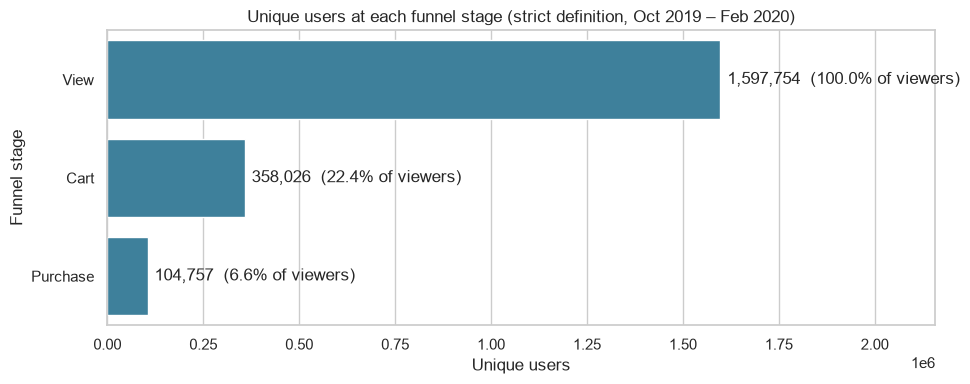

In [37]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.barplot(data=funnel_table, y="stage", x="users", color="#2E86AB", ax=ax)
ax.bar_label(
    ax.containers[0],
    labels=[f"{u:,.0f}  ({s:.1f}% of viewers)" for u, s in zip(funnel_table["users"], funnel_table["of_viewers_%"])],
    padding=5,
)
ax.set_xlim(0, funnel_table["users"].max() * 1.35)
ax.set_title(f"Unique users at each funnel stage ({FUNNEL_MODE} definition, Oct 2019 – Feb 2020)")
ax.set_xlabel("Unique users")
ax.set_ylabel("Funnel stage")
plt.tight_layout()
plt.show()


In [38]:

step_rates = {"view→cart": overall_rates["view_to_cart"], "cart→purchase": overall_rates["cart_to_purchase"]}
weakest_step = min(step_rates, key=step_rates.get)
print(f"Takeaway: of {views:,} viewers, {overall_rates['view_to_purchase'] * 100:.1f}% complete a purchase; "
      f"the weakest step is {weakest_step} ({step_rates[weakest_step] * 100:.1f}%).")

Takeaway: of 1,597,754 viewers, 6.6% complete a purchase; the weakest step is view→cart (22.4%).


## 3. Conversion Breakdown by Category

In [39]:
category_null_share = funnel_events.loc[funnel_events["event_type"] == "view", "category_code"].isna().mean() * 100
view_events_by_category = (
    funnel_events[(funnel_events["event_type"] == "view") & funnel_events["category_code"].notna()]
    .groupby("category_code", observed=True)
    .size()
    .nlargest(TOP_N_CATEGORIES)
)


In [40]:
top_categories = [str(c) for c in view_events_by_category.index]
print(f"View events without category_code : {category_null_share:.1f}% (excluded from the ranking)")


View events without category_code : 97.6% (excluded from the ranking)


In [41]:
category_funnel = funnel_by_group(funnel_events, "category_code", top_categories)
category_funnel["view_events"] = category_funnel["category_code"].map({str(k): v for k, v in view_events_by_category.items()})
category_funnel["small_sample"] = category_funnel["view_users"] < MIN_VIEWERS
category_funnel = category_funnel.sort_values("view_events", ascending=False).reset_index(drop=True)


In [42]:

rate_cols = ["view_to_cart_%", "cart_to_purchase_%", "view_to_purchase_%"]
display(category_funnel[["category_code", "view_events", "view_users", "cart_users_strict", "purchase_users_strict", *rate_cols, "small_sample"]])

,category_code,view_events,view_users,cart_users_strict,purchase_users_strict,view_to_cart_%,cart_to_purchase_%,view_to_purchase_%,small_sample
0,appliances.environment.vacuum,113752,33987,6674,2500,19.64,37.46,7.36,False
1,furniture.living_room.cabinet,26246,13378,1135,200,8.48,17.62,1.49,False
2,accessories.bag,22572,9486,496,148,5.23,29.84,1.56,False
3,apparel.glove,20736,9646,3874,1868,40.16,48.22,19.37,False
4,stationery.cartrige,20583,10124,2413,1131,23.83,46.87,11.17,False
5,furniture.bathroom.bath,15087,8049,1601,573,19.89,35.79,7.12,False
6,appliances.personal.hair_cutter,4660,2379,167,44,7.02,26.35,1.85,False
7,appliances.personal.massager,2822,1335,121,31,9.06,25.62,2.32,False


In [43]:
heat = category_funnel.set_index("category_code")[rate_cols]
heat.columns = ["view→cart", "cart→purchase", "view→purchase"]
ranked = category_funnel.sort_values("view_to_purchase_%", ascending=False)


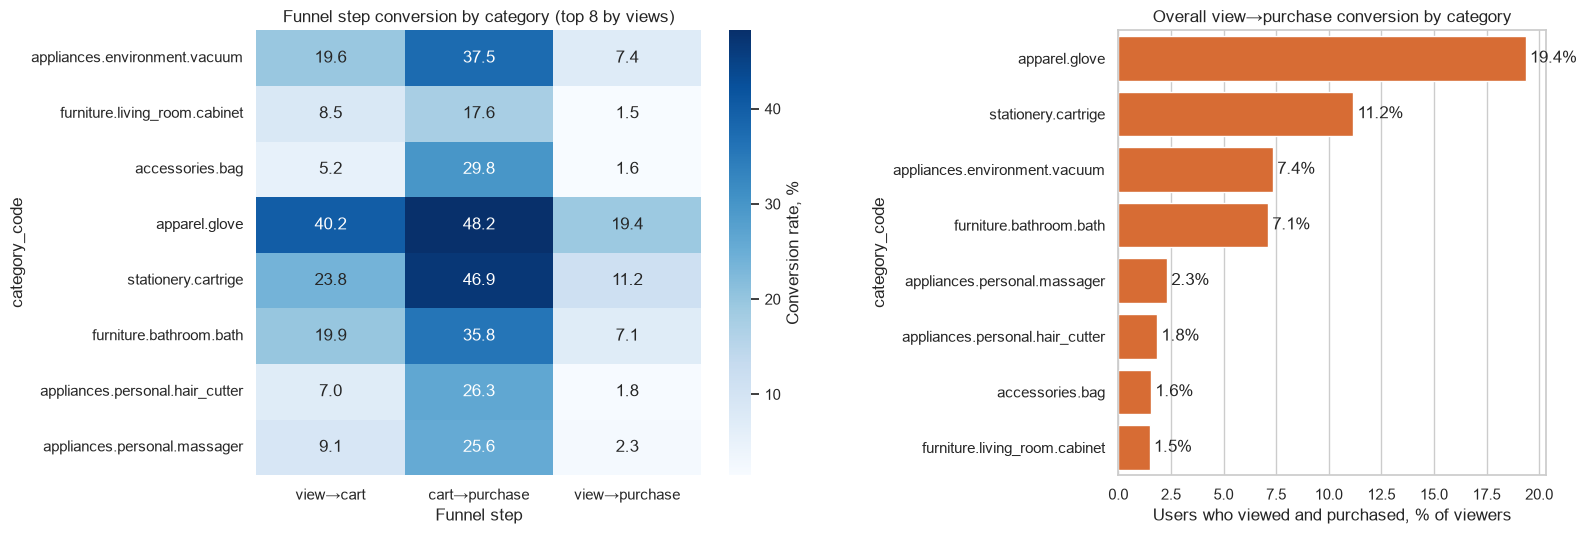

In [44]:

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(heat, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "Conversion rate, %"}, ax=axes[0])
axes[0].set_title("Funnel step conversion by category (top 8 by views)")
axes[0].set_xlabel("Funnel step")
axes[0].set_ylabel("category_code")

sns.barplot(data=ranked, y="category_code", x="view_to_purchase_%", color="#F26419", ax=axes[1])
axes[1].bar_label(axes[1].containers[0], fmt="%.1f%%", padding=3)
axes[1].set_title("Overall view→purchase conversion by category")
axes[1].set_xlabel("Users who viewed and purchased, % of viewers")
axes[1].set_ylabel("category_code")
plt.tight_layout(w_pad=5)
plt.show()


In [45]:

best_cat = ranked.iloc[0]
worst_cat = ranked.iloc[-1]
print(f"Takeaway: `{best_cat['category_code']}` converts at {best_cat['view_to_purchase_%']:.1f}% vs "
      f"{worst_cat['view_to_purchase_%']:.1f}% for `{worst_cat['category_code']}` "
      f"({safe_ratio(best_cat['view_to_purchase_%'], worst_cat['view_to_purchase_%']):.1f}× gap). "
      f"This is an association between category and conversion, not proof that the category causes it.")

Takeaway: `apparel.glove` converts at 19.4% vs 1.5% for `furniture.living_room.cabinet` (13.0× gap). This is an association between category and conversion, not proof that the category causes it.


## 4. Monthly Funnel and January vs February

In [46]:
def two_proportion_test(successes_a: int, n_a: int, successes_b: int, n_b: int) -> dict[str, float]:
    """Two-sided pooled z-test for two proportions plus Cohen's h."""
    p_a, p_b = safe_ratio(successes_a, n_a), safe_ratio(successes_b, n_b)
    pooled = safe_ratio(successes_a + successes_b, n_a + n_b)
    std_error = math.sqrt(pooled * (1 - pooled) * (1 / n_a + 1 / n_b)) if n_a and n_b else float("nan")
    z_score = (p_b - p_a) / std_error if std_error else float("nan")
    p_value = math.erfc(abs(z_score) / math.sqrt(2)) if not math.isnan(z_score) else float("nan")
    cohen_h = 2 * math.asin(math.sqrt(p_b)) - 2 * math.asin(math.sqrt(p_a))
    return {"p_a": p_a, "p_b": p_b, "z": z_score, "p_value": p_value, "cohen_h": cohen_h}


In [47]:


def effect_label(h: float) -> str:
    """Conventional wording for Cohen's h."""
    size = abs(h)
    return "negligible" if size < 0.2 else "small" if size < 0.5 else "medium" if size < 0.8 else "large"


In [48]:


first_month, second_month = COMPARE_MONTHS
monthly_counts = {m: build_funnel(funnel_events[funnel_events["month"] == m]) for m in MONTH_ORDER}
monthly_stages = {m: stage_counts(monthly_counts[m]) for m in MONTH_ORDER}  # (viewers, carters, buyers)


In [49]:

monthly_table = pd.DataFrame(
    {
        m: {
            "view_users": monthly_stages[m][0],
            "cart_users": monthly_stages[m][1],
            "purchase_users": monthly_stages[m][2],
            **{f"{k}_%": v * 100 for k, v in funnel_rates(monthly_counts[m]).items()},
        }
        for m in MONTH_ORDER
    }
).T


In [50]:
count_cols = ["view_users", "cart_users", "purchase_users"]
monthly_table[count_cols] = monthly_table[count_cols].astype(int)
print(f"Monthly funnel ({FUNNEL_MODE} definition, each month on its own):")
display(monthly_table)


Monthly funnel (strict definition, each month on its own):


,view_users,cart_users,purchase_users,view_to_cart_%,cart_to_purchase_%,view_to_purchase_%
2019-10,388331,123260,23938,31.74,19.42,6.16
2019-11,355643,84260,29532,23.69,35.05,8.30
2019-12,358212,72359,23711,20.20,32.77,6.62
2020-01,397775,81202,26295,20.41,32.38,6.61
2020-02,379246,78315,23990,20.65,30.63,6.33


In [51]:

viewers_first = stage_users(funnel_events[funnel_events["month"] == first_month])["view"]
viewers_second = stage_users(funnel_events[funnel_events["month"] == second_month])["view"]
overlap = len(np.intersect1d(viewers_first, viewers_second))
print(f"Viewers active in both {first_month} and {second_month} : {overlap:,} "
      f"({safe_ratio(overlap, len(viewers_second)) * 100:.1f}% of {second_month} viewers)")

Viewers active in both 2020-01 and 2020-02 : 60,034 (15.8% of 2020-02 viewers)


In [52]:
trend_long = (
    monthly_table[["view_to_cart_%", "cart_to_purchase_%", "view_to_purchase_%"]]
    .set_axis(["view→cart", "cart→purchase", "view→purchase"], axis=1)
    .rename_axis("month")
    .reset_index()
    .melt(id_vars="month", var_name="step", value_name="rate_%")
)


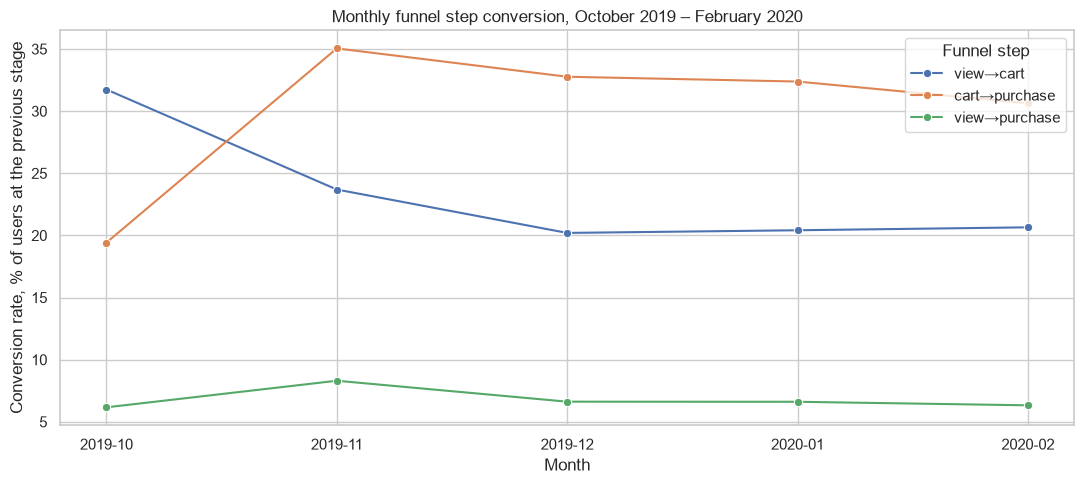

Takeaway: monthly view→purchase conversion ranges from 6.16% (2019-10) to 8.30% (2019-11); the average month sits at 6.80%.


In [53]:
fig, ax = plt.subplots(figsize=(11, 5))
sns.lineplot(data=trend_long, x="month", y="rate_%", hue="step", marker="o", ax=ax)
ax.set_title("Monthly funnel step conversion, October 2019 – February 2020")
ax.set_xlabel("Month")
ax.set_ylabel("Conversion rate, % of users at the previous stage")
ax.legend(title="Funnel step")
plt.tight_layout()
plt.show()

monthly_overall = monthly_table["view_to_purchase_%"]
print(f"Takeaway: monthly view→purchase conversion ranges from {monthly_overall.min():.2f}% ({monthly_overall.idxmin()}) "
      f"to {monthly_overall.max():.2f}% ({monthly_overall.idxmax()}); the average month sits at {monthly_overall.mean():.2f}%.")

In [54]:
STEP_DEFINITIONS = {"view→cart": (1, 0), "cart→purchase": (2, 1), "view→purchase": (2, 0)}  # (numerator, denominator) stage index
alpha_adjusted = ALPHA / len(STEP_DEFINITIONS)


In [55]:

test_rows = {}
for step, (num_idx, den_idx) in STEP_DEFINITIONS.items():
    result = two_proportion_test(
        monthly_stages[first_month][num_idx], monthly_stages[first_month][den_idx],
        monthly_stages[second_month][num_idx], monthly_stages[second_month][den_idx],
    )
    test_rows[step] = {
        f"{first_month}_%": result["p_a"] * 100,
        f"{second_month}_%": result["p_b"] * 100,
        "diff_pp": (result["p_b"] - result["p_a"]) * 100,
        "z": result["z"],
        "p_value": result["p_value"],
        "cohen_h": result["cohen_h"],
        "effect": effect_label(result["cohen_h"]),
        "decision": "Reject H0" if result["p_value"] < alpha_adjusted else "Fail to reject H0",
    }
month_tests = pd.DataFrame(test_rows).T
for col in [f"{first_month}_%", f"{second_month}_%", "diff_pp", "z", "p_value", "cohen_h"]:
    month_tests[col] = month_tests[col].astype(float)
display(month_tests)


,2020-01_%,2020-02_%,diff_pp,z,p_value,cohen_h,effect,decision
view→cart,20.41,20.65,0.24,2.58,0.01,0.01,negligible,Reject H0
cart→purchase,32.38,30.63,-1.75,-7.52,0.00,-0.04,negligible,Reject H0
view→purchase,6.61,6.33,-0.28,-5.10,0.00,-0.01,negligible,Reject H0


In [56]:

overall_test = month_tests.loc["view→purchase"]
print(f"\nAdjusted alpha = {alpha_adjusted:.4f}")
print(f"Conclusion (view→purchase): {overall_test['decision']}: "
      f"the rate moved from {overall_test[f'{first_month}_%']:.2f}% to {overall_test[f'{second_month}_%']:.2f}% "
      f"({overall_test['diff_pp']:+.2f} pp), effect size {overall_test['effect']} (h = {overall_test['cohen_h']:.3f}).")


Adjusted alpha = 0.0167
Conclusion (view→purchase): Reject H0: the rate moved from 6.61% to 6.33% (-0.28 pp), effect size negligible (h = -0.012).


In [57]:
alpha_mom = ALPHA / (len(MONTH_ORDER) - 1)
mom_rows = []
for previous, current in zip(MONTH_ORDER[:-1], MONTH_ORDER[1:]):
    result = two_proportion_test(
        monthly_stages[previous][2], monthly_stages[previous][0],
        monthly_stages[current][2], monthly_stages[current][0],
    )
    mom_rows.append({
        "from": previous,
        "to": current,
        "from_%": result["p_a"] * 100,
        "to_%": result["p_b"] * 100,
        "diff_pp": (result["p_b"] - result["p_a"]) * 100,
        "p_value": result["p_value"],
        "cohen_h": result["cohen_h"],
        "effect": effect_label(result["cohen_h"]),
        "decision": "Reject H0" if result["p_value"] < alpha_mom else "Fail to reject H0",
    })
mom_table = pd.DataFrame(mom_rows)
mom_table["abs_diff_pp"] = mom_table["diff_pp"].abs()
print(f"Month-over-month view→purchase change (adjusted alpha = {alpha_mom:.4f}):")
display(mom_table)


Month-over-month view→purchase change (adjusted alpha = 0.0125):


,from,to,from_%,to_%,diff_pp,p_value,cohen_h,effect,decision,abs_diff_pp
0,2019-10,2019-11,6.16,8.30,2.14,0.00,0.08,negligible,Reject H0,2.14
1,2019-11,2019-12,8.30,6.62,-1.68,0.00,-0.06,negligible,Reject H0,1.68
2,2019-12,2020-01,6.62,6.61,-0.01,0.88,-0.00,negligible,Fail to reject H0,0.01
3,2020-01,2020-02,6.61,6.33,-0.28,0.00,-0.01,negligible,Reject H0,0.28


In [58]:

compare_mask = (mom_table["from"] == first_month) & (mom_table["to"] == second_month)
assert compare_mask.any(), "COMPARE_MONTHS must be two consecutive months from MONTH_ORDER"
mom_largest = mom_table.loc[mom_table["abs_diff_pp"].idxmax()]
mom_rank = int(mom_table["abs_diff_pp"].rank(ascending=False)[compare_mask].iloc[0])
print(f"\n{first_month}→{second_month} is the #{mom_rank} largest of {len(mom_table)} month-over-month moves; "
      f"the largest is {mom_largest['from']}→{mom_largest['to']} ({mom_largest['diff_pp']:+.2f} pp).")


2020-01→2020-02 is the #3 largest of 4 month-over-month moves; the largest is 2019-10→2019-11 (+2.14 pp).


In [59]:
monthly_long = (
    month_tests[[f"{first_month}_%", f"{second_month}_%"]]
    .rename(columns=lambda c: c.replace("_%", ""))
    .rename_axis("step")
    .reset_index()
    .melt(id_vars="step", var_name="month", value_name="rate_%")
)

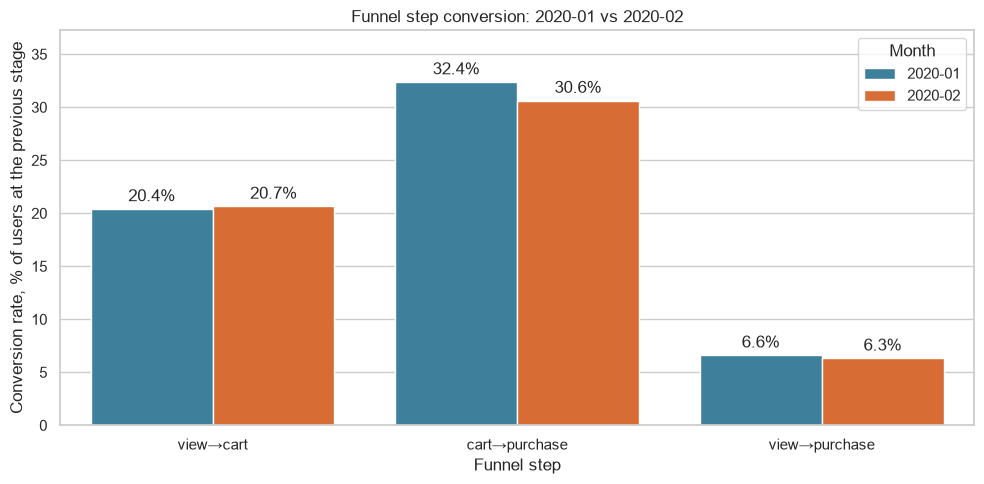

In [60]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=monthly_long, x="step", y="rate_%", hue="month", palette=["#2E86AB", "#F26419"], ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)
ax.set_title(f"Funnel step conversion: {first_month} vs {second_month}")
ax.set_xlabel("Funnel step")
ax.set_ylabel("Conversion rate, % of users at the previous stage")
ax.set_ylim(0, monthly_long["rate_%"].max() * 1.15)
ax.legend(title="Month")
plt.tight_layout()
plt.show()

In [61]:

direction = "improved" if overall_test["diff_pp"] > 0 else "declined"
print(f"Takeaway: overall view→purchase conversion {direction} by {abs(overall_test['diff_pp']):.2f} pp "
      f"({first_month} → {second_month}), the #{mom_rank} largest of {len(mom_table)} monthly moves; "
      f"decision: {overall_test['decision']} at the adjusted level. "
      f"Seasonality or a promotion may explain the change; only a controlled experiment can show a cause.")

Takeaway: overall view→purchase conversion declined by 0.28 pp (2020-01 → 2020-02), the #3 largest of 4 monthly moves; decision: Reject H0 at the adjusted level. Seasonality or a promotion may explain the change; only a controlled experiment can show a cause.


## 5. Top Brands

In [62]:
purchases = funnel_events[funnel_events["event_type"] == "purchase"]
branded_purchases = purchases[purchases["brand"].notna()]


In [63]:

brand_summary = (
    branded_purchases.groupby("brand", observed=True)
    .agg(purchase_events=("user_id", "size"), purchasers=("user_id", "nunique"), revenue=("price", "sum"))
    .nlargest(TOP_N_BRANDS, "purchase_events")
    .reset_index()
)
brand_summary["brand"] = brand_summary["brand"].astype(str)


In [64]:

brand_funnel = funnel_by_group(funnel_events, "brand", brand_summary["brand"].tolist())
brand_table = brand_summary.merge(brand_funnel[["brand", "view_users", "view_to_purchase_%"]], on="brand", how="left")
brand_table["purchase_share_%"] = brand_table["purchase_events"] / len(purchases) * 100
brand_table["cumulative_share_%"] = brand_table["purchase_share_%"].cumsum()
display(brand_table)


,brand,purchase_events,purchasers,revenue,view_users,view_to_purchase_%,purchase_share_%,cumulative_share_%
0,runail,111408,35411,"343,433.19",193942,13.33,8.66,8.66
1,irisk,73806,30391,"223,903.38",153750,13.25,5.73,14.39
2,masura,49751,12799,"139,764.86",81397,11.31,3.87,18.26
3,grattol,49542,17150,"266,295.94",106093,11.99,3.85,22.11
4,bpw.style,37943,11097,"44,636.28",42573,17.77,2.95,25.05
5,ingarden,27411,12231,"124,606.04",54166,14.70,2.13,27.18
6,estel,19438,9190,"121,788.76",92359,7.31,1.51,28.69
7,uno,17586,9226,"190,719.46",51384,10.42,1.37,30.06
8,freedecor,17467,6184,"22,714.03",24692,16.84,1.36,31.42
9,italwax,17105,7166,"104,057.29",45764,10.13,1.33,32.75


In [65]:

top5_share_all = brand_table["purchase_events"].head(5).sum() / len(purchases) * 100
top5_share_branded = brand_table["purchase_events"].head(5).sum() / len(branded_purchases) * 100
top10_share_all = brand_table["purchase_events"].sum() / len(purchases) * 100
print(f"Purchases without brand      : {(1 - len(branded_purchases) / len(purchases)) * 100:.1f}%")
print(f"Top 5 brands share           : {top5_share_all:.1f}% of all purchases ({top5_share_branded:.1f}% of branded purchases)")
print(f"Top 10 brands share          : {top10_share_all:.1f}% of all purchases")

Purchases without brand      : 42.7%
Top 5 brands share           : 25.1% of all purchases (43.7% of branded purchases)
Top 10 brands share          : 32.7% of all purchases


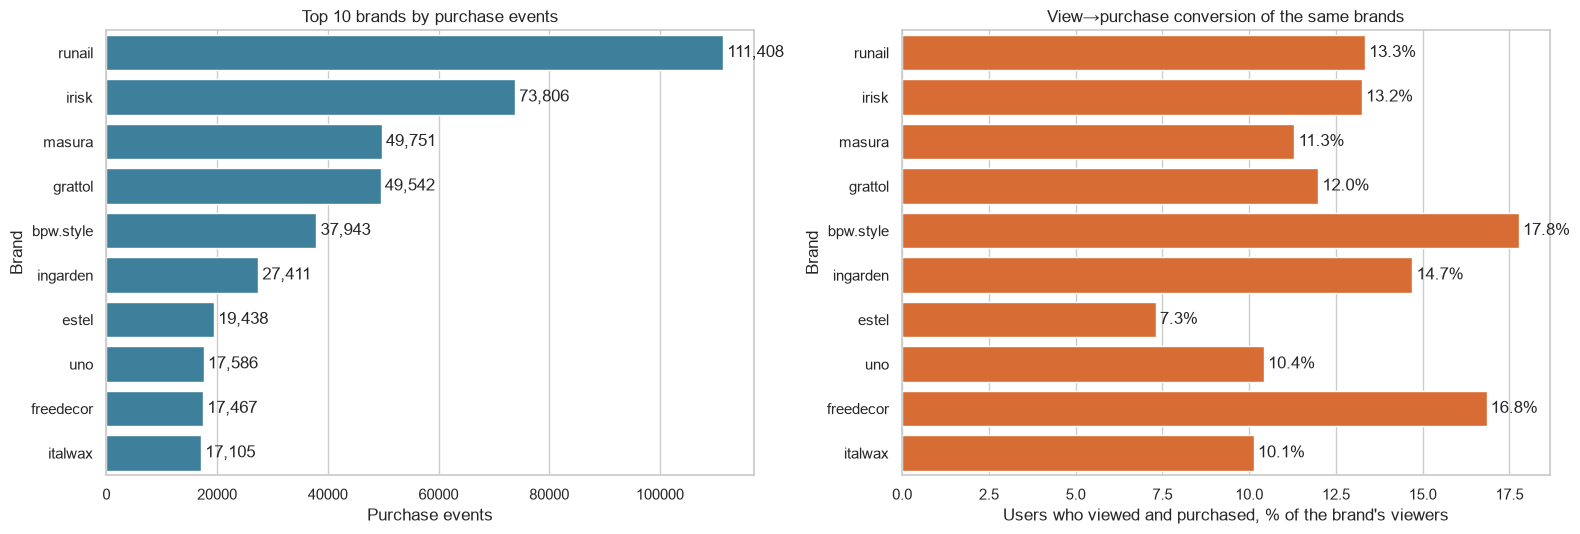

In [66]:
order = brand_table["brand"].tolist()
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
sns.barplot(data=brand_table, y="brand", x="purchase_events", order=order, color="#2E86AB", ax=axes[0])
axes[0].bar_label(axes[0].containers[0], fmt="{:,.0f}", padding=3)
axes[0].set_title("Top 10 brands by purchase events")
axes[0].set_xlabel("Purchase events")
axes[0].set_ylabel("Brand")

sns.barplot(data=brand_table, y="brand", x="view_to_purchase_%", order=order, color="#F26419", ax=axes[1])
axes[1].bar_label(axes[1].containers[0], fmt="%.1f%%", padding=3)
axes[1].set_title("View→purchase conversion of the same brands")
axes[1].set_xlabel("Users who viewed and purchased, % of the brand's viewers")
axes[1].set_ylabel("Brand")
plt.tight_layout()
plt.show()


In [67]:

best_brand = brand_table.loc[brand_table["view_to_purchase_%"].idxmax()]
worst_brand = brand_table.loc[brand_table["view_to_purchase_%"].idxmin()]
print(f"Takeaway: the top 5 brands generate {top5_share_all:.1f}% of purchases; among the top 10, "
      f"`{best_brand['brand']}` converts at {best_brand['view_to_purchase_%']:.1f}% vs {worst_brand['view_to_purchase_%']:.1f}% for `{worst_brand['brand']}`.")

Takeaway: the top 5 brands generate 25.1% of purchases; among the top 10, `bpw.style` converts at 17.8% vs 7.3% for `estel`.


## 6. Price Outliers in Purchase Events

In [68]:
purchase_prices = purchases["price"].dropna()
q1, q3 = purchase_prices.quantile([0.25, 0.75])
iqr = q3 - q1
lower_fence, upper_fence = q1 - IQR_MULTIPLIER * iqr, q3 + IQR_MULTIPLIER * iqr
outlier_mask = (purchase_prices < lower_fence) | (purchase_prices > upper_fence)


In [69]:

outlier_count = int(outlier_mask.sum())
outlier_share = outlier_count / len(purchase_prices) * 100
outlier_revenue_share = purchase_prices[outlier_mask].sum() / purchase_prices.sum() * 100


In [70]:

print(f"Purchase events with price : {len(purchase_prices):,}")
print(f"Q1 / Q3 / IQR              : {q1:,.2f} / {q3:,.2f} / {iqr:,.2f}")
print(f"Fences (lower / upper)     : {lower_fence:,.2f} / {upper_fence:,.2f}")
print(f"Outliers                   : {outlier_count:,} ({outlier_share:.2f}% of purchases, {outlier_revenue_share:.1f}% of revenue)")
print(f"Mean vs median price       : {purchase_prices.mean():,.2f} vs {purchase_prices.median():,.2f}")
print(f"Max purchase price         : {purchase_prices.max():,.2f}")


Purchase events with price : 1,287,007
Q1 / Q3 / IQR              : 1.59 / 5.40 / 3.81
Fences (lower / upper)     : -4.13 / 11.12
Outliers                   : 90,657 (7.04% of purchases, 34.9% of revenue)
Mean vs median price       : 4.93 vs 3.00
Max purchase price         : 327.78


In [71]:

display(
    purchases.nlargest(10, "price")[["event_time", "product_id", "brand", "category_code", "price"]]
    .assign(brand=lambda t: t["brand"].astype(object).fillna("unknown"),
            category_code=lambda t: t["category_code"].astype(object).fillna("unknown"))
)


,event_time,product_id,brand,category_code,price
10604421,2019-12-15 10:33:46,5906221,strong,unknown,327.78
11174807,2019-12-19 16:46:14,5906221,strong,unknown,327.78
14618303,2020-01-19 03:56:22,5906221,strong,unknown,327.78
17720670,2020-02-08 19:05:54,5906221,strong,unknown,327.78
20212745,2020-02-26 15:31:17,5906221,strong,unknown,327.78
19802546,2020-02-23 20:09:11,5723944,unknown,unknown,317.46
7674707,2019-11-24 18:35:08,5906221,strong,unknown,311.38
722986,2019-10-06 08:17:35,89343,unknown,furniture.living_room.cabinet,299.81
1140961,2019-10-08 13:11:39,89343,unknown,furniture.living_room.cabinet,299.81
1414084,2019-10-10 12:51:58,89343,unknown,furniture.living_room.cabinet,299.81


In [72]:

baskets = purchases.groupby("session_id")["price"].sum()
basket_q1, basket_q3 = baskets.quantile([0.25, 0.75])
basket_upper_fence = basket_q3 + IQR_MULTIPLIER * (basket_q3 - basket_q1)

In [73]:
print(f"\nPurchasing sessions        : {len(baskets):,}")
print(f"Basket value mean / median : {baskets.mean():,.2f} / {baskets.median():,.2f}")
print(f"Basket value max           : {baskets.max():,.2f}")
print(f"Baskets above IQR fence    : {(baskets > basket_upper_fence).sum():,} (fence = {basket_upper_fence:,.2f})")


Purchasing sessions        : 155,617
Basket value mean / median : 40.79 / 29.21
Basket value max           : 1,738.10
Baskets above IQR fence    : 9,340 (fence = 99.62)


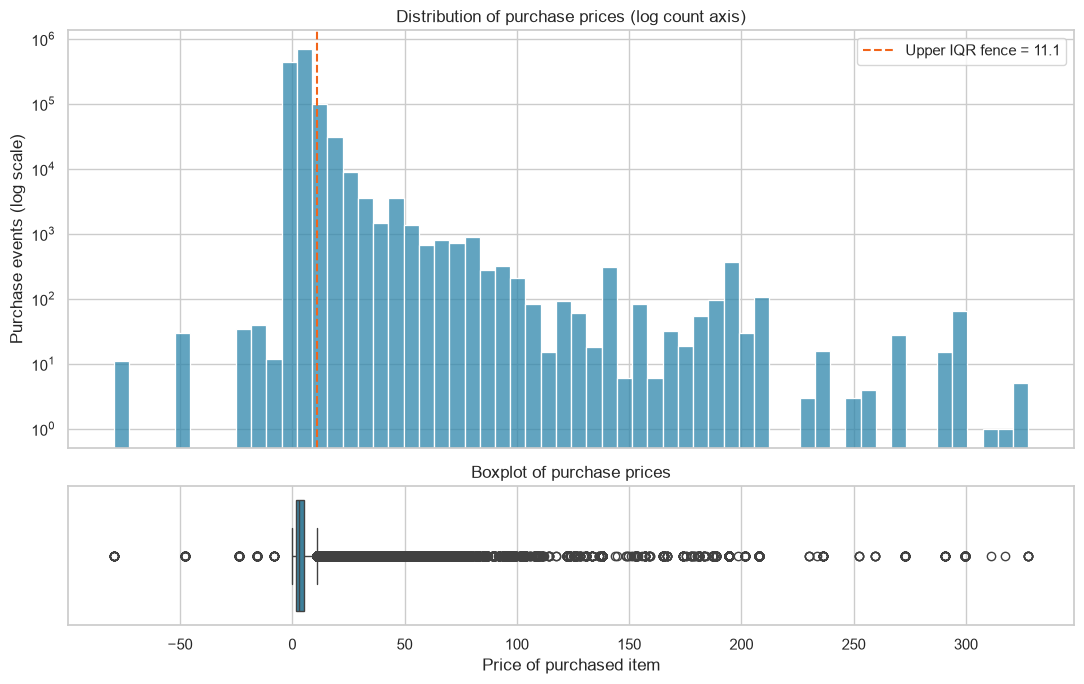

In [74]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
sns.histplot(purchase_prices, bins=60, color="#2E86AB", ax=axes[0])
axes[0].axvline(upper_fence, color="#F26419", linestyle="--", label=f"Upper IQR fence = {upper_fence:,.1f}")
axes[0].set_yscale("log")
axes[0].set_title("Distribution of purchase prices (log count axis)")
axes[0].set_ylabel("Purchase events (log scale)")
axes[0].legend()

sns.boxplot(x=purchase_prices, color="#2E86AB", ax=axes[1])
axes[1].set_title("Boxplot of purchase prices")
axes[1].set_xlabel("Price of purchased item")
axes[1].set_ylabel("")
plt.tight_layout()
plt.show()


In [75]:

skew_note = (
    "the mean sits above the median, so averages should be read next to medians"
    if purchase_prices.mean() > purchase_prices.median()
    else "the mean is not above the median, so the high prices do not skew the average"
)
print(f"Takeaway: {outlier_share:.2f}% of purchases lie above {upper_fence:,.1f} and carry {outlier_revenue_share:.1f}% of revenue; "
      f"mean {purchase_prices.mean():,.1f} vs median {purchase_prices.median():,.1f}: {skew_note}.")

Takeaway: 7.04% of purchases lie above 11.1 and carry 34.9% of revenue; mean 4.9 vs median 3.0: the mean sits above the median, so averages should be read next to medians.


## 7. Bonus Analyses



### 7.1 Time between view and purchase

In [76]:
view_events = funnel_events.loc[
    funnel_events["event_type"] == "view",
    ["user_id", "product_id", "event_time", "brand", "category_code", "price"],
]


In [77]:

first_view_user = view_events.groupby("user_id")["event_time"].min().rename("first_view")
first_purchase_user = purchases.groupby("user_id")["event_time"].min().rename("first_purchase")
user_times = pd.concat([first_view_user, first_purchase_user], axis=1, join="inner")
user_times["hours"] = (user_times["first_purchase"] - user_times["first_view"]).dt.total_seconds() / 3600
user_times_valid = user_times[user_times["hours"] >= 0]


In [78]:

first_view_pair = view_events.groupby(["user_id", "product_id"])["event_time"].min().rename("first_view")
first_purchase_pair = purchases.groupby(["user_id", "product_id"])["event_time"].min().rename("first_purchase")
pair_times = pd.concat([first_view_pair, first_purchase_pair], axis=1, join="inner")
pair_times["hours"] = (pair_times["first_purchase"] - pair_times["first_view"]).dt.total_seconds() / 3600
pair_times_valid = pair_times[pair_times["hours"] >= 0]


In [79]:


def summarise_hours(hours: pd.Series) -> dict[str, float]:
    """Distribution summary of a duration series in hours."""
    return {
        "n": len(hours),
        "mean_h": hours.mean(),
        "median_h": hours.median(),
        "p25_h": hours.quantile(0.25),
        "p75_h": hours.quantile(0.75),
        "p90_h": hours.quantile(0.90),
        "within_1h_%": (hours <= 1).mean() * 100,
        "within_24h_%": (hours <= 24).mean() * 100,
    }


time_summary = pd.DataFrame({
    "user level": summarise_hours(user_times_valid["hours"]),
    "user × product level": summarise_hours(pair_times_valid["hours"]),
}).T
display(time_summary)


,n,mean_h,median_h,p25_h,p75_h,p90_h,within_1h_%,within_24h_%
user level,"102,237.00",285.93,8.18,0.43,263.75,"1,030.86",36.80,56.24
user × product level,"450,507.00",99.62,1.25,0.27,36.39,243.04,47.24,71.56


In [80]:

print(f"User-level pairs excluded (first purchase before first view) : {len(user_times) - len(user_times_valid):,} of {len(user_times):,}")
print(f"User×product pairs excluded (no view before the purchase)    : {len(pair_times) - len(pair_times_valid):,} of {len(pair_times):,}")

User-level pairs excluded (first purchase before first view) : 2,969 of 105,206
User×product pairs excluded (no view before the purchase)    : 35,697 of 486,204


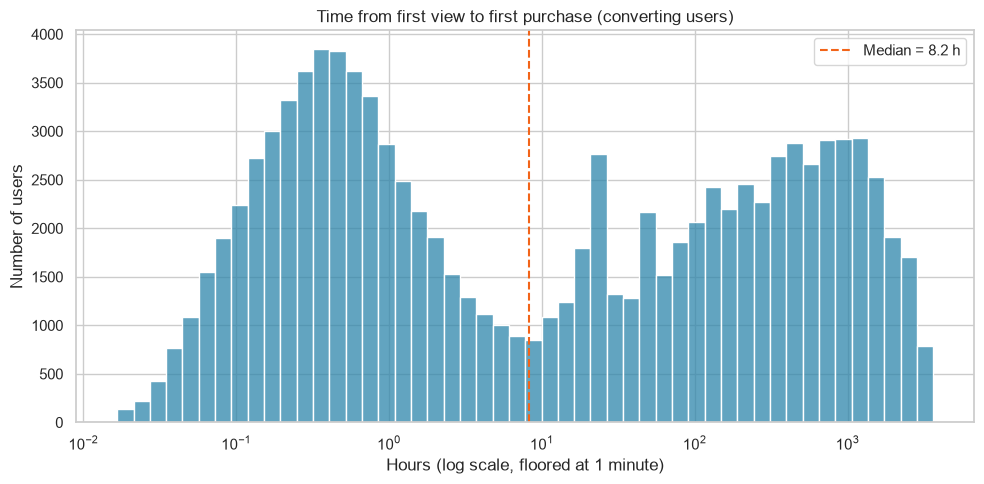

In [81]:
plot_hours = user_times_valid["hours"].clip(lower=1 / 60)  # floor at 1 minute so the log axis works
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(plot_hours, bins=50, log_scale=True, color="#2E86AB", ax=ax)
median_hours = user_times_valid["hours"].median()
ax.axvline(median_hours if median_hours > 0 else 1 / 60, color="#F26419", linestyle="--", label=f"Median = {median_hours:.1f} h")
ax.set_title("Time from first view to first purchase (converting users)")
ax.set_xlabel("Hours (log scale, floored at 1 minute)")
ax.set_ylabel("Number of users")
ax.legend()
plt.tight_layout()
plt.show()


In [82]:

user_stats = time_summary.loc["user level"]
tail_note = (
    "The mean is far above the median, so a long tail of slow deciders exists."
    if user_stats["mean_h"] > 2 * user_stats["median_h"]
    else "Mean and median are close, so decision time is fairly even across users."
)
print(f"Takeaway: the median converter buys {user_stats['median_h']:.1f} h after the first view "
      f"(mean {user_stats['mean_h']:.1f} h); {user_stats['within_24h_%']:.0f}% buy within 24 h and "
      f"{user_stats['within_1h_%']:.0f}% within one hour. {tail_note}")

Takeaway: the median converter buys 8.2 h after the first view (mean 285.9 h); 56% buy within 24 h and 37% within one hour. The mean is far above the median, so a long tail of slow deciders exists.


### 7.2 Products viewed often but rarely purchased

In [83]:
product_views = view_events.groupby("product_id").agg(
    view_events=("user_id", "size"),
    viewers=("user_id", "nunique"),
    brand=("brand", "first"),
    category_code=("category_code", "first"),
    median_price=("price", "median"),
)


In [84]:
converted_viewers = pair_times_valid.reset_index().groupby("product_id")["user_id"].nunique().rename("converted_viewers")
product_stats = product_views.join(converted_viewers).fillna({"converted_viewers": 0})
product_stats["conversion_%"] = product_stats["converted_viewers"] / product_stats["viewers"] * 100

eligible = product_stats[product_stats["viewers"] >= MIN_VIEWERS].copy()
benchmark_rate = eligible["converted_viewers"].sum() / eligible["viewers"].sum() * 100
view_threshold = eligible["viewers"].quantile(VIEW_QUANTILE)


In [85]:

eligible["segment"] = np.where(
    (eligible["viewers"] >= view_threshold) & (eligible["conversion_%"] < benchmark_rate),
    "High views, low conversion",
    "Other products",
)
eligible["missed_purchases"] = eligible["viewers"] * (benchmark_rate - eligible["conversion_%"]) / 100
flagged = eligible[eligible["segment"] == "High views, low conversion"].sort_values("missed_purchases", ascending=False)


In [86]:

print(f"Products with views            : {len(product_stats):,}")
print(f"Eligible (≥ {MIN_VIEWERS} viewers)       : {len(eligible):,}")
print(f"Benchmark product conversion   : {benchmark_rate:.2f}%")
print(f"High-view threshold (p{VIEW_QUANTILE * 100:.0f})     : {view_threshold:,.0f} unique viewers")
print(f"Flagged products               : {len(flagged):,}")


Products with views            : 53,854
Eligible (≥ 100 viewers)       : 13,731
Benchmark product conversion   : 6.66%
High-view threshold (p95)     : 1,288 unique viewers
Flagged products               : 418


In [87]:

display(
    flagged.head(10)
    .reset_index()
    .assign(brand=lambda t: t["brand"].astype(object).fillna("unknown"),
            category_code=lambda t: t["category_code"].astype(object).fillna("unknown"))
    [["product_id", "brand", "category_code", "median_price", "viewers", "conversion_%", "missed_purchases"]]
)

,product_id,brand,category_code,median_price,viewers,conversion_%,missed_purchases
0,5877456,jessnail,unknown,122.22,15150,0.34,957.09
1,5808664,ardell,unknown,6.37,10660,0.33,675.03
2,5856186,runail,unknown,75.40,13215,1.73,652.21
3,5769877,kapous,unknown,3.65,10110,0.80,592.39
4,5877454,jessnail,unknown,44.29,15716,3.18,547.79
5,5886282,unknown,unknown,21.59,11534,2.21,513.24
6,5896420,jessnail,unknown,49.21,8479,0.68,506.76
7,5649236,concept,unknown,8.65,13621,3.05,491.25
8,5804820,unknown,unknown,63.33,10347,1.91,491.18
9,5892179,unknown,unknown,18.89,9635,1.96,452.75


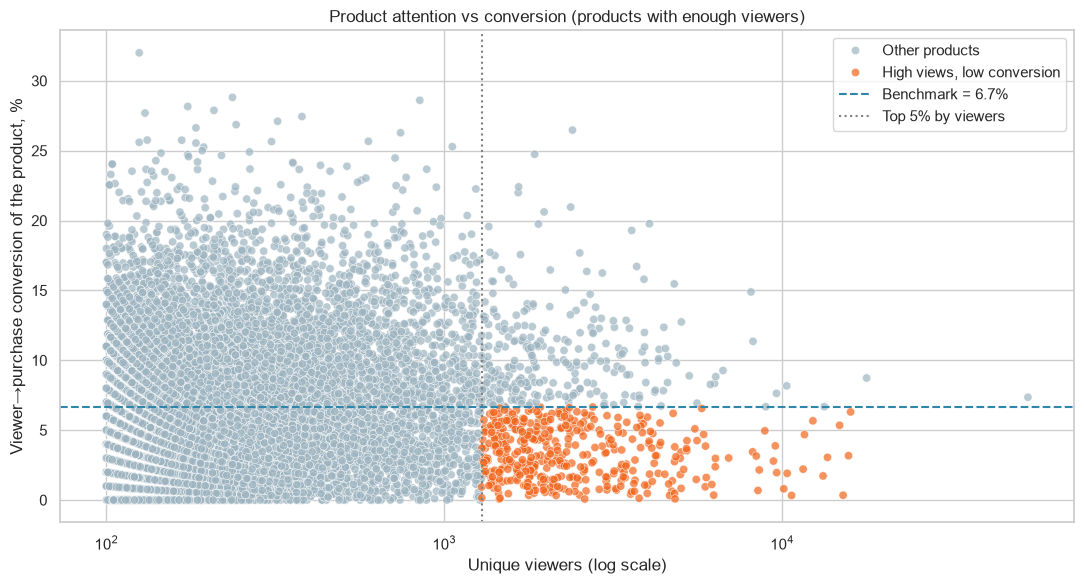

In [88]:
fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(
    data=eligible.reset_index(), x="viewers", y="conversion_%", hue="segment",
    palette={"Other products": "#9DB4C0", "High views, low conversion": "#F26419"}, alpha=0.7, ax=ax,
)
ax.axhline(benchmark_rate, color="#2E86AB", linestyle="--", label=f"Benchmark = {benchmark_rate:.1f}%")
ax.axvline(view_threshold, color="grey", linestyle=":", label=f"Top {100 - VIEW_QUANTILE * 100:.0f}% by viewers")
ax.set_xscale("log")
ax.set_title("Product attention vs conversion (products with enough viewers)")
ax.set_xlabel("Unique viewers (log scale)")
ax.set_ylabel("Viewer→purchase conversion of the product, %")
ax.legend()
plt.tight_layout()
plt.show()


In [89]:

flagged_view_share = flagged["view_events"].sum() / product_stats["view_events"].sum() * 100
missed_total = flagged["missed_purchases"].sum()
print(f"Takeaway: {len(flagged):,} products absorb {flagged_view_share:.1f}% of all product views while converting below the "
      f"{benchmark_rate:.1f}% benchmark; at benchmark conversion they would add about {missed_total:,.0f} purchases.")

Takeaway: 418 products absorb 17.8% of all product views while converting below the 6.7% benchmark; at benchmark conversion they would add about 41,335 purchases.


## 8. Reconciliation with the Reference Notes

In [90]:
first_note, second_note = NOTE_MONTHS
scope = funnel_events[funnel_events["month"].isin(NOTE_MONTHS)]
scope_purchases = scope[scope["event_type"] == "purchase"]


In [91]:

scope_totals = {stage: int((scope["event_type"] == stage).sum()) for stage in FUNNEL_STAGES}
scope_event_share = {stage: scope_totals[stage] / sum(scope_totals.values()) * 100 for stage in FUNNEL_STAGES}
scope_event_rates = {
    "view_to_cart": safe_ratio(scope_totals["cart"], scope_totals["view"]) * 100,
    "cart_to_purchase": safe_ratio(scope_totals["purchase"], scope_totals["cart"]) * 100,
    "view_to_purchase": safe_ratio(scope_totals["purchase"], scope_totals["view"]) * 100,
}
event_matrix = pd.crosstab(scope["month"], scope["event_type"])[FUNNEL_STAGES]
event_conversion_by_month = event_matrix["purchase"] / event_matrix["view"] * 100


In [92]:

scope_rates = funnel_rates(build_funnel(scope))
scope_branded = scope_purchases[scope_purchases["brand"].notna()]
top5_scope = scope_branded.groupby("brand", observed=True).size().nlargest(5).sum() / len(scope_purchases) * 100
scope_baskets = scope_purchases.groupby("session_id")["price"].sum()


In [93]:

main_category_funnel = funnel_by_group(scope, "category_main")
main_eligible = main_category_funnel[main_category_funnel["view_users"] >= MIN_VIEWERS]
best_main = main_eligible.loc[main_eligible["view_to_purchase_%"].idxmax()]
accessories_row = main_category_funnel[main_category_funnel["category_main"] == "accessories"]
accessories_rate = float(accessories_row["view_to_purchase_%"].iloc[0]) if len(accessories_row) else float("nan")


In [94]:

reference_rows = [
    (f"Rows, {first_note}", NOTE["rows_jan"], float(rows_by_month[first_note])),
    (f"Rows, {second_note}", NOTE["rows_feb"], float(rows_by_month[second_note])),
    ("View share of events, % (event-level)", NOTE["view_share"], scope_event_share["view"]),
    ("Cart share of events, % (event-level)", NOTE["cart_share"], scope_event_share["cart"]),
    ("Purchase share of events, % (event-level)", NOTE["purchase_share"], scope_event_share["purchase"]),
    ("View→cart, % (event-level)", NOTE["view_to_cart"], scope_event_rates["view_to_cart"]),
    ("Cart→purchase, % (event-level)", NOTE["cart_to_purchase"], scope_event_rates["cart_to_purchase"]),
    ("View→purchase, % (event-level)", NOTE["view_to_purchase"], scope_event_rates["view_to_purchase"]),
    ("Feb − Jan conversion, pp (event-level)", NOTE["feb_minus_jan_pp"],
     float(event_conversion_by_month[second_note] - event_conversion_by_month[first_note])),
    ("Feb − Jan conversion, pp (user-level)", NOTE["feb_minus_jan_pp"], float(overall_test["diff_pp"])),
    ("Top-level category `accessories`, view→purchase % (Jan+Feb)", NOTE["accessories_rate"], accessories_rate),
    ("Top 5 brands, % of all purchases (Jan+Feb)", NOTE["top5_brand_share"], top5_scope),
    ("Average basket value (Jan+Feb)", NOTE["avg_basket"], float(scope_baskets.mean())),
    ("Maximum basket value (Jan+Feb)", NOTE["max_basket"], float(scope_baskets.max())),
    ("View→cart, % (user-level, Jan+Feb, no note value)", np.nan, scope_rates["view_to_cart"] * 100),
    ("Cart→purchase, % (user-level, Jan+Feb, no note value)", np.nan, scope_rates["cart_to_purchase"] * 100),
    ("View→purchase, % (user-level, Jan+Feb, no note value)", np.nan, scope_rates["view_to_purchase"] * 100),
    ("View→purchase, % (user-level, all five months, no note value)", np.nan, overall_rates["view_to_purchase"] * 100),
]
reference_check = pd.DataFrame(reference_rows, columns=["metric", "note", "computed"])
reference_check["difference"] = reference_check["computed"] - reference_check["note"]
reference_check["relative_diff_%"] = reference_check["difference"] / reference_check["note"] * 100
reference_check["status"] = np.where(
    reference_check["note"].isna(), "—",
    np.where(reference_check["relative_diff_%"].abs() <= 10, "close", "differs"),
)
display(reference_check.style.format({"note": "{:,.2f}", "computed": "{:,.2f}", "difference": "{:,.2f}", "relative_diff_%": "{:,.1f}"}, na_rep="—"))

print(f"Best top-level category by view→purchase (Jan+Feb): `{best_main['category_main']}` ({best_main['view_to_purchase_%']:.1f}%)")

,metric,note,computed,difference,relative_diff_%,status
0,"Rows, 2020-01","2,600,000.00","4,264,752.00","1,664,752.00",64.0,differs
1,"Rows, 2020-02","1,700,000.00","4,156,682.00","2,456,682.00",144.5,differs
2,"View share of events, % (event-level)",85.10,58.75,-26.35,-31.0,differs
3,"Cart share of events, % (event-level)",8.70,33.81,25.11,288.6,differs
4,"Purchase share of events, % (event-level)",6.20,7.44,1.24,20.1,differs
5,"View→cart, % (event-level)",10.20,57.55,47.35,464.2,differs
6,"Cart→purchase, % (event-level)",71.40,22.02,-49.38,-69.2,differs
7,"View→purchase, % (event-level)",7.30,12.67,5.37,73.6,differs
8,"Feb − Jan conversion, pp (event-level)",0.80,-0.56,-1.36,-169.9,differs
9,"Feb − Jan conversion, pp (user-level)",0.80,-0.28,-1.08,-135.6,differs


Best top-level category by view→purchase (Jan+Feb): `apparel` (17.9%)


## 9. Final Summary

### Key Findings and Business Recommendations



#### Insight 1



**FACT:** Of 1,597,754 users who viewed products, 358,026 added items to their carts (22.4%). Of those who added items to their carts, 104,757 completed a purchase, representing a 29.3% cart-to-purchase conversion rate and a 6.6% overall view-to-purchase conversion rate. Among converters, the median time from first view to purchase was 8.2 hours, and 56% purchased within 24 hours.

**ACTION:** Prioritize A/B testing product-page improvements, including price and offer visibility, customer reviews, and add-to-cart button prominence. Since 56% of converters purchase within 24 hours, test timely reminders and retargeting campaigns within this window.

**CONFIDENCE:** Medium. The analysis covers user-level activity from October 2019 to February 2020. Behaviour before October 2019 is not captured, which may affect funnel attribution.



#### Insight 2



**FACT:** The view-to-purchase conversion rate fell from 6.61% in January 2020 to 6.33% in February, a decrease of 0.28 percentage points. The adjusted-alpha statistical test rejected the null hypothesis, although the effect size was negligible (Cohen’s *h* = −0.012).

**CONTEXT:** This was the third-largest of the four month-over-month changes. The largest occurred between October and November 2019, when conversion increased by 2.14 percentage points.

**ACTION:** Investigate changes in promotions, traffic composition, pricing, and seasonality during February before attributing the decline to a specific factor. If a potential driver is identified, validate its impact through a controlled A/B test.

**CONFIDENCE:** Low to Medium. Although the decline is statistically significant, the five-month observational period and absence of a control group limit causal conclusions.



#### Insight 3 



**FACT:** Among the eight highest-ranked categories, `apparel.glove` recorded the highest view-to-purchase conversion rate at 19.4%, while `furniture.living_room.cabinet` recorded the lowest at 1.5%—a difference of approximately 13×. However, 98% of view events lack a `category_code` and are excluded from this comparison.

**ACTION:** Examine the leading category's pricing, product presentation, and assortment for practices worth testing elsewhere. Audit the lowest-converting category for potential pricing, availability, and product-page issues. Improve category tracking to make the analysis more representative of overall traffic.

**CONFIDENCE:** Medium. Conversion differences may reflect product prices, purchase intent, and category-specific customer behaviour rather than product-page quality alone.



#### Insight 4



**FACT:** The five leading brands account for 25.1% of all purchases with known brand information, while the top ten account for 32.7%. Within the top ten, `bpw.style` has a view-to-purchase conversion rate of 17.8%, compared with 7.3% for `estel`. Approximately 43% of purchases have no recorded brand.

**ACTION:** Monitor inventory and product visibility for leading brands to reduce potential lost sales. Investigate differences in pricing, stock availability, and product content among high-volume brands with relatively low conversion rates. Improve brand-data completeness to support more reliable comparisons.

**CONFIDENCE:** Medium. Missing brand information limits the representativeness of brand-level purchase shares and conversion estimates.



#### Insight 5



**FACT:** A total of 418 heavily viewed products convert below the 6.7% benchmark and account for 17.8% of all product views. If these products reached the benchmark while maintaining the same level of viewing activity, they could generate approximately 41,335 additional purchases. Purchases priced above 11.1 are classified as IQR outliers; they represent 7.04% of purchases and 34.9% of revenue. These observations were retained in the analysis.

**ACTION:** Prioritize the flagged products for investigation, focusing on price competitiveness, stock availability, product images, and customer reviews. Cross-reference the flagged products with high-priced outlier purchases before implementing pricing changes. Test targeted product-page improvements before rolling them out broadly.

**CONFIDENCE:** Medium. Below-benchmark conversion does not necessarily indicate a product-page problem; customers may be comparing alternatives or checking prices without intending to purchase immediately. Controlled A/B tests can help distinguish these explanations.



#### Overall Business Priority



The findings suggest three immediate priorities:

1. **Improve funnel efficiency:** Test interventions at the view-to-cart stage, where the largest drop-off occurs.
2. **Investigate underperforming products and categories:** Prioritize high-traffic products with below-benchmark conversion and examine differences in pricing, availability, and customer intent.
3. **Improve tracking and measurement:** Address missing category and brand data to strengthen segmentation, conversion analysis, and future business decisions.

These recommendations should be treated as testable hypotheses rather than proven causal explanations. Prioritize interventions based on expected business impact, validate them through controlled experiments where feasible, and monitor both conversion rate and revenue to avoid optimizing one metric at the expense of another.